# Dijkstra vs Policy (Common Routes Only)

This section compares both algorithms only on `(start_idx, target_idx)` pairs that exist in both CSV files.

- Success/completion is defined from `failed_error` (as requested).
- Completion-time comparisons include box plot, mean bar chart, and histogram.
- Route-level plots use a consistent `route_index` after sorting by `(start_idx, target_idx)`.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

# --- User-editable algorithm selectors ---
# Fill these two variables as needed
algo1 = "dij"
algo2 = "310837de"

# --- Helpers ---
def resolve_algo_dir(runs_root: Path, algo_hint: str) -> Path:
    algo_hint = algo_hint.strip().lower()
    candidates = [p for p in runs_root.iterdir() if p.is_dir()]

    # 1) exact match
    exact = [p for p in candidates if p.name.lower() == algo_hint]
    if exact:
        return exact[0]

    # 2) startswith / contains
    fuzzy = [
        p for p in candidates
        if p.name.lower().startswith(algo_hint) or algo_hint in p.name.lower()
    ]
    if len(fuzzy) == 1:
        return fuzzy[0]
    if len(fuzzy) > 1:
        # choose shortest name as most specific compact match
        return sorted(fuzzy, key=lambda p: (len(p.name), p.name))[0]

    raise ValueError(f"No algorithm directory found under {runs_root} for hint: {algo_hint}")


def latest_test_csv(algo_dir: Path) -> Path:
    tests = [p for p in algo_dir.glob("test_*") if p.is_dir()]
    if not tests:
        raise ValueError(f"No test_* directories found in {algo_dir}")

    def test_index(path: Path):
        m = re.match(r"test_(\d+)$", path.name)
        return int(m.group(1)) if m else -1

    tests_sorted = sorted(
        tests,
        key=lambda p: (test_index(p), p.stat().st_mtime),
    )
    selected = tests_sorted[-1]
    csv_path = selected / "simulation_results.csv"
    if not csv_path.exists():
        raise ValueError(f"Missing simulation_results.csv in {selected}")
    return csv_path


def is_completed_from_failed_error(series: pd.Series) -> pd.Series:
    as_str = series.astype("string").str.strip().str.lower()
    return series.isna() | as_str.isin(["", "na", "nan", "none"])


# --- Inputs ---
runs_root = Path("../runs/trsp")
algo1_dir = resolve_algo_dir(runs_root, algo1)
algo2_dir = resolve_algo_dir(runs_root, algo2)

algo1_csv = latest_test_csv(algo1_dir)
# algo1_csv = "/home/shinobi-owl/PhD/battery/DroneSim/runs/trsp/dijkstra/test_5/simulation_results.csv"
algo2_csv = latest_test_csv(algo2_dir)

algo1_label = algo1_dir.name
algo2_label = algo2_dir.name

key_cols = ["start_idx", "target_idx"]
time_col = "total_time_taken"
path_col = "path_edges"
success_col = "failed_error"
required_cols = key_cols + [time_col, path_col, success_col]

# --- Load ---
df_algo1 = pd.read_csv(algo1_csv)
df_algo2 = pd.read_csv(algo2_csv)

for name, df in [(algo1_label, df_algo1), (algo2_label, df_algo2)]:
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{name} missing required columns: {missing}")

# enforce types
for df in [df_algo1, df_algo2]:
    df["start_idx"] = pd.to_numeric(df["start_idx"], errors="coerce").astype("Int64")
    df["target_idx"] = pd.to_numeric(df["target_idx"], errors="coerce").astype("Int64")
    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")

# optional duplicate checks on route keys
dup_algo1 = df_algo1.duplicated(subset=key_cols).sum()
dup_algo2 = df_algo2.duplicated(subset=key_cols).sum()
print(f"Duplicate route keys -> {algo1_label}: {dup_algo1}, {algo2_label}: {dup_algo2}")
print(f"Using files -> {algo1_label}: {algo1_csv}")
print(f"Using files -> {algo2_label}: {algo2_csv}")

# --- SUCCESS-FIRST filtering ---
# Keep only successful rows per algorithm first
# success = failed_error is NA-like AND total_time_taken > 0
success_algo1_full = is_completed_from_failed_error(df_algo1[success_col]) & (df_algo1[time_col] > 0)
success_algo2_full = is_completed_from_failed_error(df_algo2[success_col]) & (df_algo2[time_col] > 0)

df_algo1_success = df_algo1.loc[success_algo1_full].copy()
df_algo2_success = df_algo2.loc[success_algo2_full].copy()

print(f"Successful rows -> {algo1_label}: {len(df_algo1_success)}/{len(df_algo1)}, {algo2_label}: {len(df_algo2_success)}/{len(df_algo2)}")

# --- Keep only common OD pairs among successful rows ---
pairs_algo1 = set(zip(df_algo1_success["start_idx"], df_algo1_success["target_idx"]))
pairs_algo2 = set(zip(df_algo2_success["start_idx"], df_algo2_success["target_idx"]))
common_pairs = pairs_algo1.intersection(pairs_algo2)

mask_algo1 = df_algo1_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)
mask_algo2 = df_algo2_success.apply(lambda r: (r["start_idx"], r["target_idx"]) in common_pairs, axis=1)

df_algo1_common = (
    df_algo1_success.loc[mask_algo1]
    .sort_values(key_cols)
    .reset_index(drop=True)
)
df_algo2_common = (
    df_algo2_success.loc[mask_algo2]
    .sort_values(key_cols)
    .reset_index(drop=True)
)

if len(df_algo1_common) != len(df_algo2_common):
    raise ValueError(
        f"Filtered row count mismatch: {algo1_label}={len(df_algo1_common)} vs {algo2_label}={len(df_algo2_common)}"
    )

# common route check
same_keys = (df_algo1_common[key_cols].values == df_algo2_common[key_cols].values).all()
if not same_keys:
    raise ValueError("Route ordering mismatch after sorting common pairs.")

# --- Adjustment: if path_edges are the same in both algos for a route,
# set both total_time_taken values to the lower of the two ---
path1 = df_algo1_common[path_col].astype("string").fillna("").str.strip()
path2 = df_algo2_common[path_col].astype("string").fillna("").str.strip()
same_path_mask = path1 == path2

min_shared_time = np.minimum(df_algo1_common[time_col].values, df_algo2_common[time_col].values)
df_algo1_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]
df_algo2_common.loc[same_path_mask, time_col] = min_shared_time[same_path_mask.values]

print(f"Rows with identical path_edges adjusted to shared min time: {int(same_path_mask.sum())}")

# route index for x-axis alignment
df_algo1_common["route_index"] = np.arange(len(df_algo1_common))
df_algo2_common["route_index"] = np.arange(len(df_algo2_common))

# route labels
route_key = (
    df_algo1_common["start_idx"].astype(str)
    + "->"
    + df_algo1_common["target_idx"].astype(str)
)
df_algo1_common["route_key"] = route_key
df_algo2_common["route_key"] = route_key

# success summary on full dfs + comparison subset size
summary = pd.DataFrame(
    {
        "algorithm": [algo1_label, algo2_label],
        "completed_routes_in_full_df": [int(success_algo1_full.sum()), int(success_algo2_full.sum())],
        "total_routes_in_full_df": [len(df_algo1), len(df_algo2)],
        "routes_used_for_comparison": [len(df_algo1_common), len(df_algo2_common)],
    }
)
summary["success_rate_pct_full_df"] = 100 * summary["completed_routes_in_full_df"] / summary["total_routes_in_full_df"]

print(f"Common successful OD pairs: {len(common_pairs)}")
print(f"Rows after success+common filter -> {algo1_label}: {len(df_algo1_common)}, {algo2_label}: {len(df_algo2_common)}")
print("\nSuccess summary:")
display(summary)

# joined frame for route-level time difference
aligned = pd.DataFrame(
    {
        "route_index": df_algo1_common["route_index"],
        "start_idx": df_algo1_common["start_idx"],
        "target_idx": df_algo1_common["target_idx"],
        "route_key": df_algo1_common["route_key"],
        f"{algo1_label}_time": df_algo1_common[time_col],
        f"{algo2_label}_time": df_algo2_common[time_col],
    }
)
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"
aligned[diff_col] = aligned[f"{algo2_label}_time"] - aligned[f"{algo1_label}_time"]

time_summary = pd.DataFrame(
    {
        "algorithm": [algo1_label, algo2_label],
        "mean_time": [df_algo1_common[time_col].mean(), df_algo2_common[time_col].mean()],
        "median_time": [df_algo1_common[time_col].median(), df_algo2_common[time_col].median()],
        "min_time": [df_algo1_common[time_col].min(), df_algo2_common[time_col].min()],
        "max_time": [df_algo1_common[time_col].max(), df_algo2_common[time_col].max()],
    }
)

print("Time summary on successful common OD routes (after same-path min-time adjustment):")
display(time_summary)

display(aligned.head(10))

Duplicate route keys -> dijkstra: 7, 310837de: 7
Using files -> dijkstra: ../runs/trsp/dijkstra/test_25/simulation_results.csv
Using files -> 310837de: ../runs/trsp/310837de/test_0/simulation_results.csv
Successful rows -> dijkstra: 98/100, 310837de: 11/100
Rows with identical path_edges adjusted to shared min time: 8
Common successful OD pairs: 11
Rows after success+common filter -> dijkstra: 11, 310837de: 11

Success summary:


,algorithm,completed_routes_in_full_df,total_routes_in_full_df,routes_used_for_comparison,success_rate_pct_full_df
0,dijkstra,98,100,11,98.0
1,310837de,11,100,11,11.0


Time summary on successful common OD routes (after same-path min-time adjustment):


,algorithm,mean_time,median_time,min_time,max_time
0,dijkstra,67.727273,45.0,8.0,173.0
1,310837de,71.727273,45.0,8.0,181.0


,route_index,start_idx,target_idx,route_key,dijkstra_time,310837de_time,time_diff_310837de_minus_dijkstra
0,0,2,1,2->1,23.0,23.0,0.0
1,1,3,7,3->7,30.0,30.0,0.0
2,2,8,7,8->7,8.0,8.0,0.0
3,3,8,17,8->17,37.0,37.0,0.0
4,4,11,6,11->6,123.0,109.0,-14.0
5,5,21,5,21->5,32.0,32.0,0.0
6,6,22,7,22->7,173.0,181.0,8.0
7,7,22,8,22->8,143.0,143.0,0.0
8,8,22,24,22->24,68.0,68.0,0.0
9,9,23,17,23->17,45.0,45.0,0.0


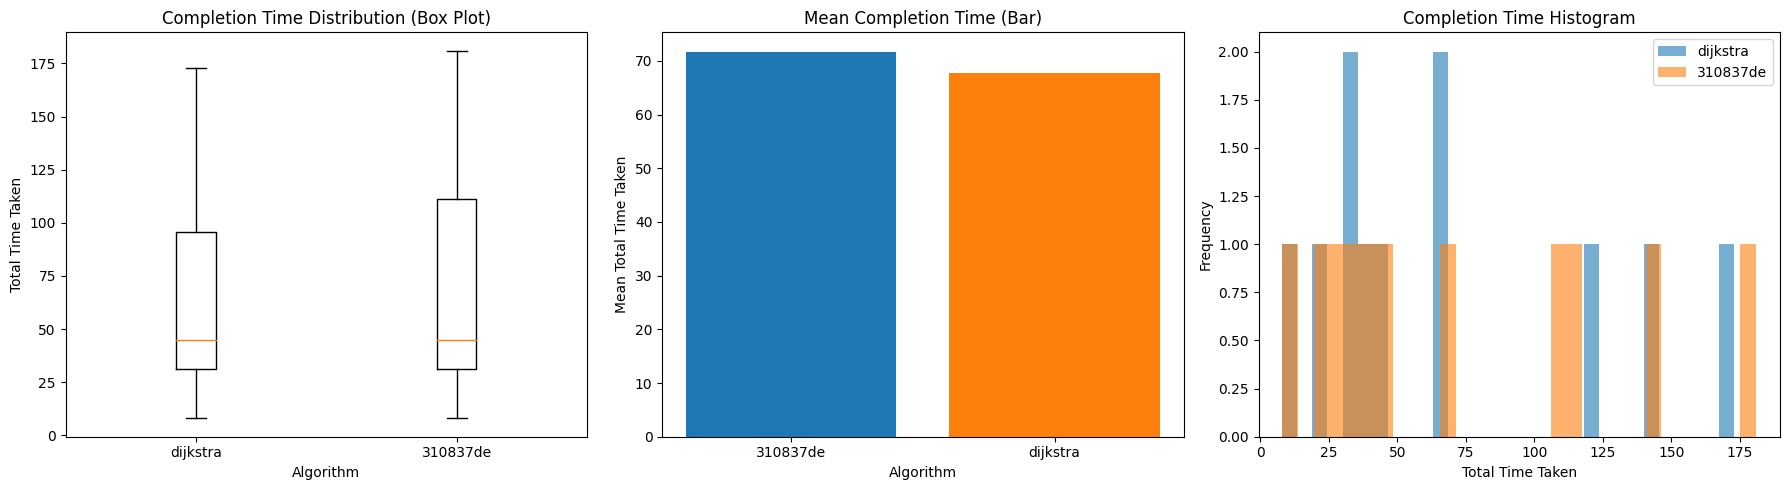

In [38]:
# --- Time comparison plots: box, mean bar, histogram ---
plot_df = pd.concat(
    [
        pd.DataFrame({"algorithm": algo1_label, "total_time_taken": df_algo1_common["total_time_taken"]}),
        pd.DataFrame({"algorithm": algo2_label, "total_time_taken": df_algo2_common["total_time_taken"]}),
    ],
    ignore_index=True,
)

means = (
    plot_df.groupby("algorithm", as_index=False)["total_time_taken"]
    .mean()
    .rename(columns={"total_time_taken": "mean_total_time_taken"})
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Box plot
algorithms = [algo1_label, algo2_label]
box_data = [
    plot_df.loc[plot_df["algorithm"] == algo, "total_time_taken"].dropna().values
    for algo in algorithms
]
axes[0].boxplot(box_data, labels=algorithms)
axes[0].set_title("Completion Time Distribution (Box Plot)")
axes[0].set_xlabel("Algorithm")
axes[0].set_ylabel("Total Time Taken")

# Mean bar chart
axes[1].bar(means["algorithm"], means["mean_total_time_taken"], color=["#1f77b4", "#ff7f0e"])
axes[1].set_title("Mean Completion Time (Bar)")
axes[1].set_xlabel("Algorithm")
axes[1].set_ylabel("Mean Total Time Taken")

# Histogram overlay
bins = 30
axes[2].hist(df_algo1_common["total_time_taken"], bins=bins, alpha=0.6, label=algo1_label)
axes[2].hist(df_algo2_common["total_time_taken"], bins=bins, alpha=0.6, label=algo2_label)
axes[2].set_title("Completion Time Histogram")
axes[2].set_xlabel("Total Time Taken")
axes[2].set_ylabel("Frequency")
axes[2].legend()

plt.tight_layout()
plt.show()

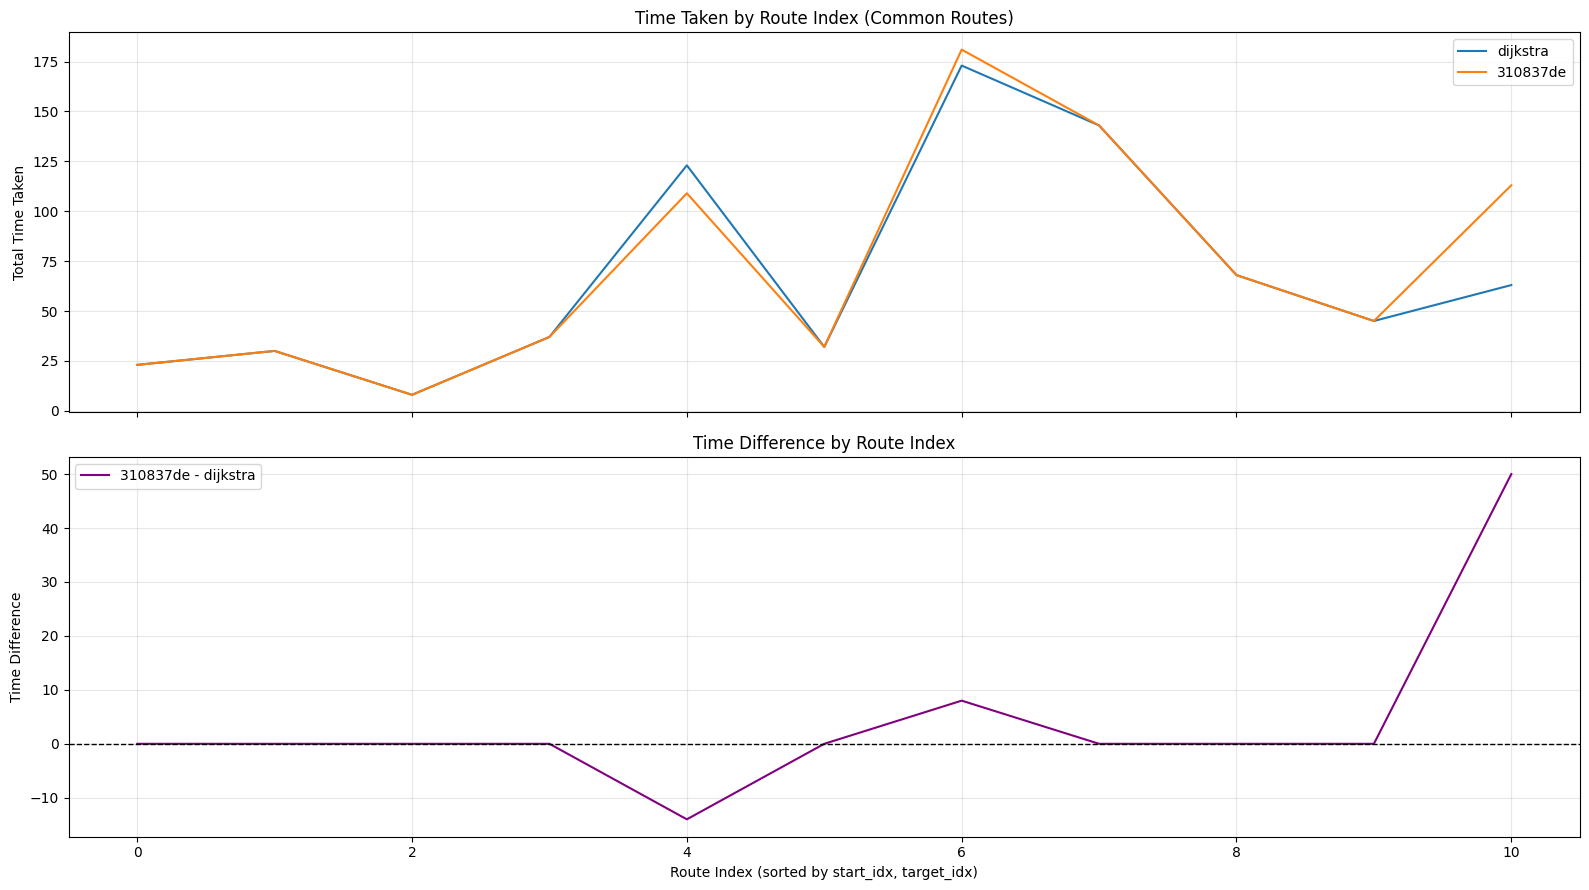

Mean time difference (310837de - dijkstra): 4.0
Routes where 310837de is faster (diff < 0): 1
Routes where dijkstra is faster (diff > 0): 2
Routes with equal time: 8


In [39]:
# --- Route index plots: raw times and time difference ---
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

axes[0].plot(aligned["route_index"], aligned[time_col_algo1], label=algo1_label, linewidth=1.5)
axes[0].plot(aligned["route_index"], aligned[time_col_algo2], label=algo2_label, linewidth=1.5)
axes[0].set_title("Time Taken by Route Index (Common Routes)")
axes[0].set_ylabel("Total Time Taken")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    aligned["route_index"],
    aligned[diff_col],
    color="purple",
    linewidth=1.5,
    label=f"{algo2_label} - {algo1_label}",
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Time Difference by Route Index")
axes[1].set_xlabel("Route Index (sorted by start_idx, target_idx)")
axes[1].set_ylabel("Time Difference")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean time difference ({algo2_label} - {algo1_label}):", aligned[diff_col].mean())
print(f"Routes where {algo2_label} is faster (diff < 0):", (aligned[diff_col] < 0).sum())
print(f"Routes where {algo1_label} is faster (diff > 0):", (aligned[diff_col] > 0).sum())
print("Routes with equal time:", (aligned[diff_col] == 0).sum())

Top 10 BEST routes for 310837de vs dijkstra (most negative diff):


,route_index,route_key,dijkstra_time,310837de_time,time_diff_310837de_minus_dijkstra
4,4,11->6,123.0,109.0,-14.0
0,0,2->1,23.0,23.0,0.0
1,1,3->7,30.0,30.0,0.0
2,2,8->7,8.0,8.0,0.0
3,3,8->17,37.0,37.0,0.0
5,5,21->5,32.0,32.0,0.0
7,7,22->8,143.0,143.0,0.0
8,8,22->24,68.0,68.0,0.0
9,9,23->17,45.0,45.0,0.0
6,6,22->7,173.0,181.0,8.0


Top 10 WORST routes for 310837de vs dijkstra (most positive diff):


,route_index,route_key,dijkstra_time,310837de_time,time_diff_310837de_minus_dijkstra
10,10,24->17,63.0,113.0,50.0
6,6,22->7,173.0,181.0,8.0
0,0,2->1,23.0,23.0,0.0
1,1,3->7,30.0,30.0,0.0
2,2,8->7,8.0,8.0,0.0
3,3,8->17,37.0,37.0,0.0
5,5,21->5,32.0,32.0,0.0
7,7,22->8,143.0,143.0,0.0
8,8,22->24,68.0,68.0,0.0
9,9,23->17,45.0,45.0,0.0


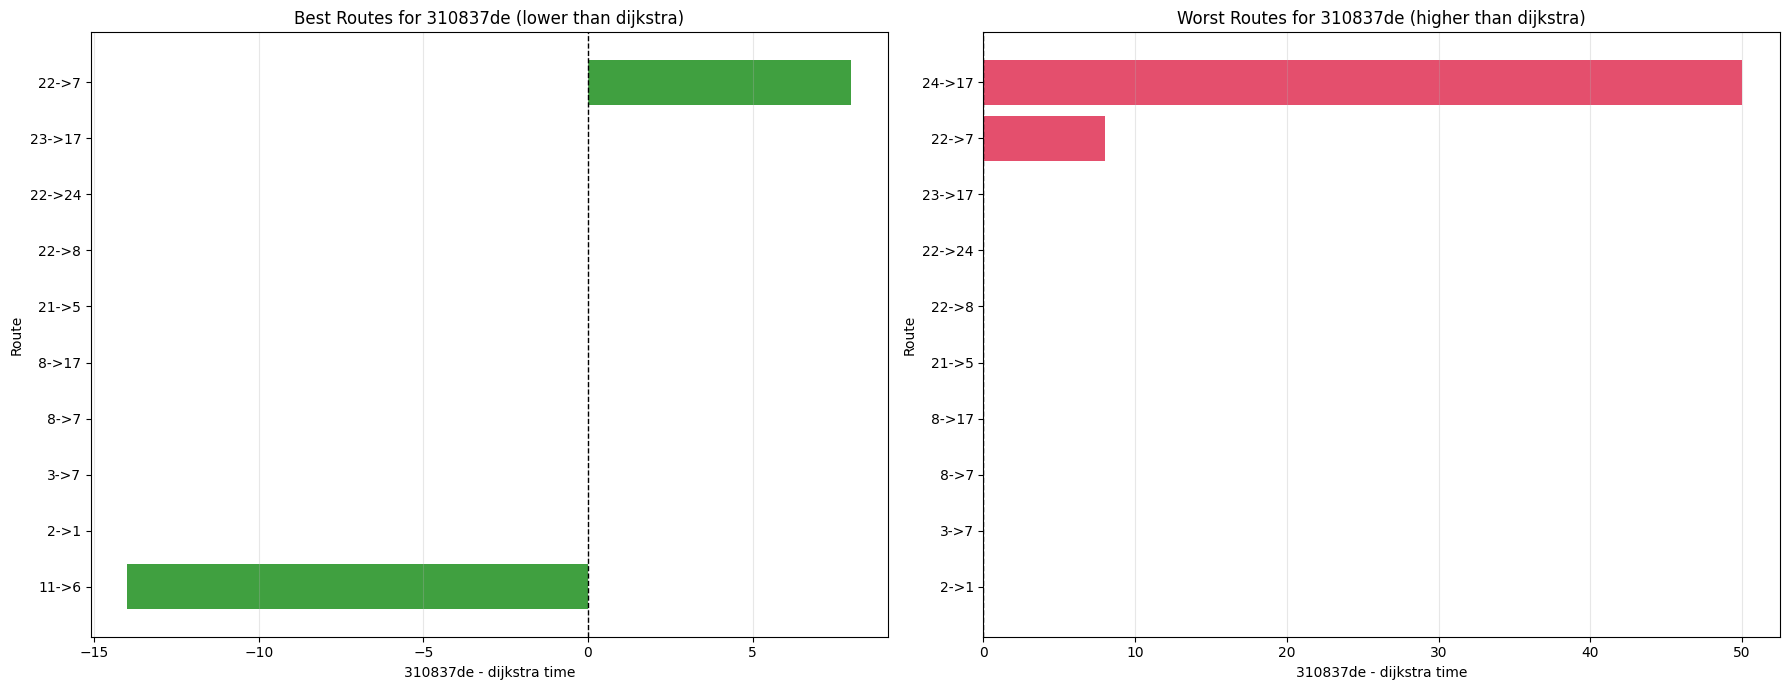

In [40]:
# --- Best and worst routes between the two algorithms ---
# diff_col is defined as: algo2_time - algo1_time
#   negative -> algo2 faster, positive -> algo1 faster

top_k = 10

time_col_algo1 = f"{algo1_label}_time"
time_col_algo2 = f"{algo2_label}_time"
diff_col = f"time_diff_{algo2_label}_minus_{algo1_label}"

best_for_algo2 = aligned.nsmallest(top_k, diff_col).copy()
worst_for_algo2 = aligned.nlargest(top_k, diff_col).copy()

show_cols = ["route_index", "route_key", time_col_algo1, time_col_algo2, diff_col]

print(f"Top {top_k} BEST routes for {algo2_label} vs {algo1_label} (most negative diff):")
display(best_for_algo2[show_cols])

print(f"Top {top_k} WORST routes for {algo2_label} vs {algo1_label} (most positive diff):")
display(worst_for_algo2[show_cols])

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=False)

left_df = best_for_algo2.sort_values(diff_col, ascending=True)
right_df = worst_for_algo2.sort_values(diff_col, ascending=True)

axes[0].barh(left_df["route_key"], left_df[diff_col], color="green", alpha=0.75)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"Best Routes for {algo2_label} (lower than {algo1_label})")
axes[0].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[0].set_ylabel("Route")
axes[0].grid(axis="x", alpha=0.3)

axes[1].barh(right_df["route_key"], right_df[diff_col], color="crimson", alpha=0.75)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title(f"Worst Routes for {algo2_label} (higher than {algo1_label})")
axes[1].set_xlabel(f"{algo2_label} - {algo1_label} time")
axes[1].set_ylabel("Route")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

---
# Aggregated Results — All Policies

Scans every `runs/trsp/*/test_N/` folder, infers `(network, traffic)` from the test config, and writes one row per `(network, traffic, model)` combination to `results/trsp_results.csv`.

For dijkstra, which has multiple test folders covering different configurations, the highest-numbered test is used when the same `(network, traffic)` appears more than once. Results can then be compared across algorithms on the same network and traffic condition.

In [41]:
import os
import yaml
import pandas as pd
import numpy as np

TRSP_DIR = '../runs/trsp'

def infer_network_id(net_path):
    # Check rand_grid_road before grid_road to avoid substring collision
    if 'rand_grid_road' in net_path: return 'N2'
    if 'grid_road'      in net_path: return 'N1'
    if 'ames'           in net_path: return 'N3'
    return 'UNKNOWN'

def infer_traffic_id(K):
    return {1: 'T1', 2: 'T2'}.get(int(K), 'UNKNOWN')

def compute_stats(csv_path):
    df = pd.read_csv(csv_path)
    df['total_time_taken'] = pd.to_numeric(df['total_time_taken'], errors='coerce')
    # pandas reads the literal string 'NA' as NaN; treat both as success (mirrors is_completed_from_failed_error)
    is_ok = df['failed_error'].isna() | \
            df['failed_error'].astype(str).str.strip().str.upper().eq('NA')
    success = df[is_ok & (df['total_time_taken'] > 0)]
    if success.empty:
        return None
    t = success['total_time_taken']
    return dict(
        makespan_mean=round(t.mean(), 2),
        makespan_med=round(t.median(), 2),
        makespan_min=round(t.min(), 2),
        makespan_max=round(t.max(), 2),
        success_rate=round(len(success) / len(df), 4),
    )

# Scan all test_N dirs; for each (network_id, traffic_id, model) keep the highest-numbered test
best = {}   # (network_id, traffic_id, model) -> (test_num, csv_path, algo)

for entry in sorted(os.listdir(TRSP_DIR)):
    policy_path = os.path.join(TRSP_DIR, entry)
    if not os.path.isdir(policy_path):
        continue
    test_names = sorted(
        [d for d in os.listdir(policy_path) if d.startswith('test_')
         and os.path.isdir(os.path.join(policy_path, d))],
        key=lambda x: int(x.split('_')[1])
    )
    for test_name in test_names:
        test_num = int(test_name.split('_')[1])
        cfg_p = os.path.join(policy_path, test_name, 'config.yaml')
        csv_p = os.path.join(policy_path, test_name, 'simulation_results.csv')
        if not (os.path.exists(cfg_p) and os.path.exists(csv_p)):
            continue
        with open(cfg_p) as f:
            cfg = yaml.safe_load(f)
        algo  = cfg['agent']['algo']
        model = 'dijkstra' if algo == 'dijkstra' else cfg['agent'].get('policy', entry)
        key   = (infer_network_id(cfg['net']['net_path']),
                 infer_traffic_id(cfg['traffic']['K']),
                 model)
        if key not in best or test_num > best[key][0]:
            best[key] = (test_num, csv_p, algo)

rows = []
for (nid, tid, model), (_, csv_p, algo) in sorted(best.items()):
    stats = compute_stats(csv_p)
    if stats is None:
        continue
    rows.append({'network': nid, 'traffic': tid, 'model': model, 'algo': algo, **stats})

results_df = pd.DataFrame(rows, columns=[
    'network', 'traffic', 'model', 'algo',
    'makespan_mean', 'makespan_med', 'makespan_min', 'makespan_max', 'success_rate'
])
results_df.to_csv('../results/trsp_results.csv', index=False)
print(f"Wrote {len(results_df)} rows → results/trsp_results.csv")
results_df

Wrote 30 rows → results/trsp_results.csv


,network,traffic,model,algo,makespan_mean,makespan_med,makespan_min,makespan_max,success_rate
0,N1,T1,5b6c4910,dqn,181.56,171.5,37.0,482.0,0.98
1,N1,T1,5dd13f39,ppo,147.30,152.0,73.0,271.0,0.10
2,N1,T1,6ca77d6d,a2c,130.08,122.0,73.0,224.0,0.12
3,N1,T1,dijkstra,dijkstra,214.04,181.0,37.0,670.0,0.98
4,N1,T1,ff58b1a9,sarsa,182.88,170.0,37.0,480.0,0.98
5,N1,T2,21937982,sarsa,198.61,181.0,37.0,468.0,0.98
6,N1,T2,4c95f436,ppo,146.29,162.5,37.0,270.0,0.14
7,N1,T2,506a3be8,dqn,195.10,180.0,37.0,452.0,0.98
8,N1,T2,dijkstra,dijkstra,229.12,215.0,37.0,675.0,0.97
9,N1,T2,ea0768c9,a2c,131.18,114.0,37.0,282.0,0.17


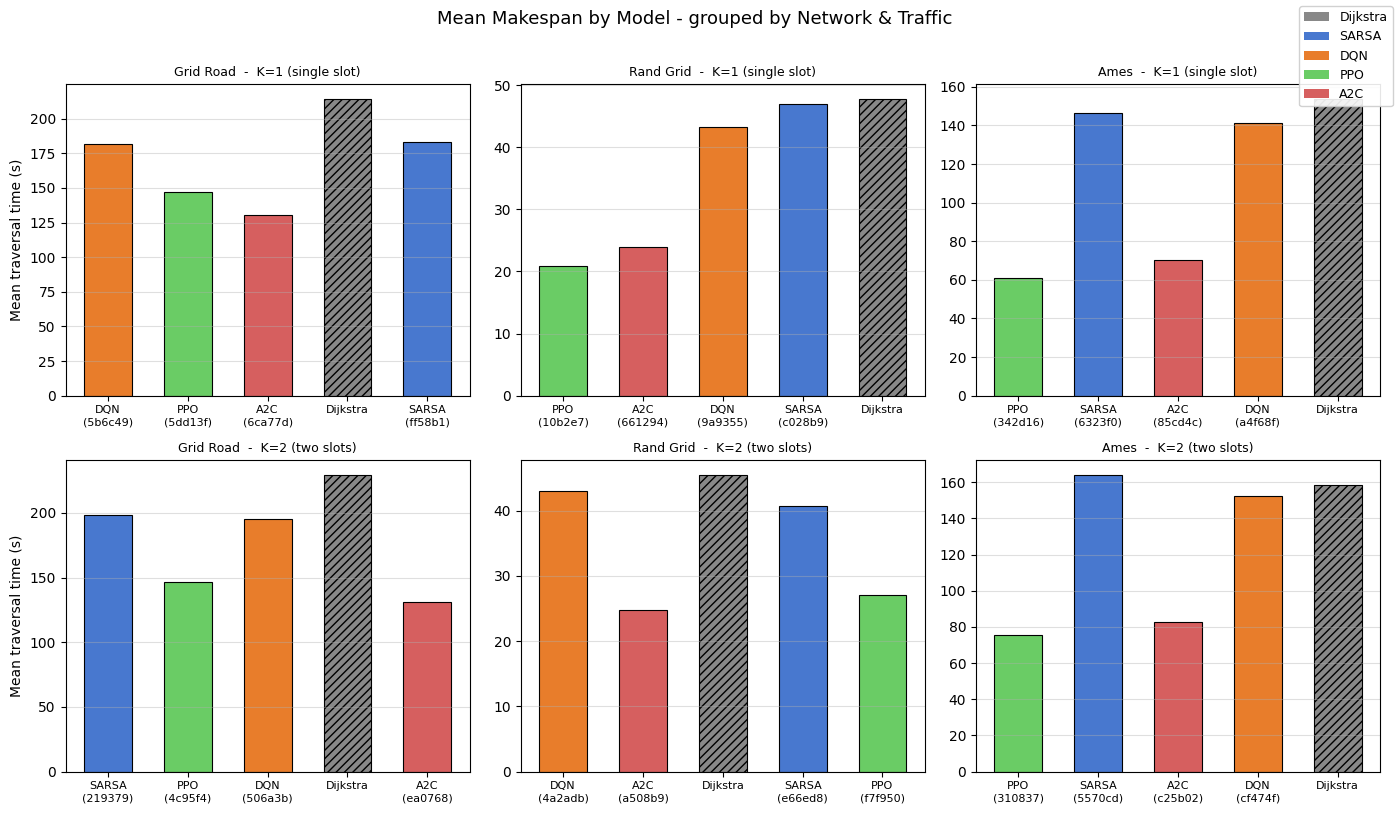

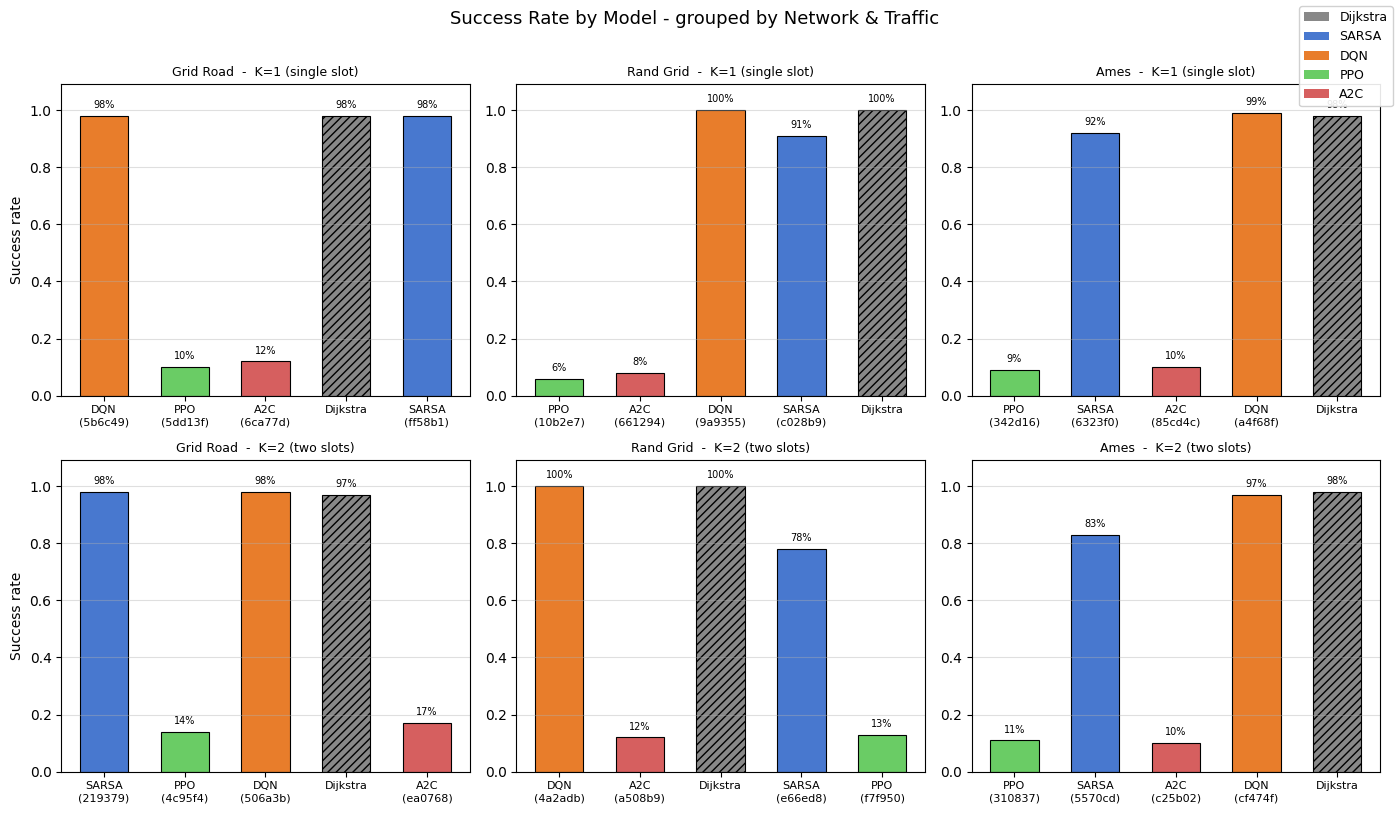

In [42]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Model -> algo lookup (built from the scan above, so no extra file I/O needed)
model_algo = {model: algo for (_, _, model), (_, _, algo) in best.items()}

ALGO_COLORS = {'dijkstra': '#888888', 'sarsa': '#4878cf', 'dqn': '#e87d2b', 'ppo': '#6acc65', 'a2c': '#d65f5f'}
ALGO_LABELS = {'dijkstra': 'Dijkstra', 'sarsa': 'SARSA', 'dqn': 'DQN', 'ppo': 'PPO', 'a2c': 'A2C'}
NET_LABELS  = {'N1': 'Grid Road', 'N2': 'Rand Grid', 'N3': 'Ames'}
TRAF_LABELS = {'T1': 'K=1 (single slot)', 'T2': 'K=2 (two slots)'}
NETWORKS    = ['N1', 'N2', 'N3']
TRAFFICS    = ['T1', 'T2']

def model_display(model):
    algo  = model_algo.get(model, model)
    label = ALGO_LABELS.get(algo, algo.upper())
    if model != 'dijkstra':
        label += f'\n({model[:6]})'
    return label

for metric, ylabel, title_prefix in [
    ('makespan_mean', 'Mean traversal time (s)', 'Mean Makespan'),
    ('success_rate',  'Success rate',            'Success Rate'),
]:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=False)
    fig.suptitle(f'{title_prefix} by Model - grouped by Network & Traffic',
                 fontsize=13, y=1.01)

    for row_i, tid in enumerate(TRAFFICS):
        for col_i, nid in enumerate(NETWORKS):
            ax = axes[row_i][col_i]
            subset = results_df[
                (results_df['network'] == nid) & (results_df['traffic'] == tid)
            ].reset_index(drop=True)

            if subset.empty:
                ax.set_visible(False)
                continue

            models  = subset['model'].tolist()
            values  = subset[metric].tolist()
            labels  = [model_display(m) for m in models]
            colors  = [ALGO_COLORS.get(model_algo.get(m, ''), '#aaaaaa') for m in models]
            hatches = ['////' if m == 'dijkstra' else '' for m in models]

            bars = ax.bar(range(len(models)), values, color=colors,
                          width=0.6, edgecolor='black', linewidth=0.8)
            for bar, hatch in zip(bars, hatches):
                bar.set_hatch(hatch)

            ax.set_xticks(range(len(models)))
            ax.set_xticklabels(labels, fontsize=8)
            ax.set_title(f'{NET_LABELS[nid]}  -  {TRAF_LABELS[tid]}', fontsize=9)
            ax.set_ylabel(ylabel if col_i == 0 else '')
            ax.grid(axis='y', alpha=0.4)
            if metric == 'success_rate':
                ax.set_ylim(0, 1.09)
                # Annotate each bar with its value
                for i, v in enumerate(values):
                    ax.text(i, v + 0.02, f'{v:.0%}', ha='center', va='bottom', fontsize=7)

    legend_patches = [
        mpatches.Patch(facecolor=ALGO_COLORS[a], label=ALGO_LABELS[a])
        for a in ['dijkstra', 'sarsa', 'dqn', 'ppo', 'a2c']
    ]
    fig.legend(handles=legend_patches, loc='upper right', fontsize=9, framealpha=0.9)
    plt.tight_layout()
    plt.show()